In [ ]:
import tensorflow as tf

(x_train, _), (_, _) = tf.keras.datasets.cifar10.load_data()

print("Dataset loaded successfully!")
print("Training data shape:", x_train.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1422s 8us/step
Dataset loaded successfully!
Training data shape: (50000, 32, 32, 3)


Dataset loaded successfully!
Training data shape: (10000, 32, 32, 3)

Starting VAE training...
Epoch 1/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 13s 69ms/step - kl_loss: 9.6330 - loss: 151.7531 - reconstruction_loss: 142.1201
Epoch 2/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 21s 72ms/step - kl_loss: 12.8266 - loss: 123.9560 - reconstruction_loss: 111.1294
Epoch 3/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 11s 72ms/step - kl_loss: 13.1606 - loss: 110.5321 - reconstruction_loss: 97.3714
Epoch 4/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 20s 71ms/step - kl_loss: 13.6406 - loss: 102.3963 - reconstruction_loss: 88.7557
Epoch 5/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 11s 70ms/step - kl_loss: 13.8431 - loss: 98.1959 - reconstruction_loss: 84.3528
Epoch 6/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 11s 69ms/step - kl_loss: 14.1485 - loss: 94.6881 - reconstruction_loss: 80.5397
Epoch 7/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 20s 65ms/step - kl_loss: 14.2693 - loss: 93.2336 - reconstruction_loss: 78.9642
Epoch 8/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 11s 68ms/step - kl_l

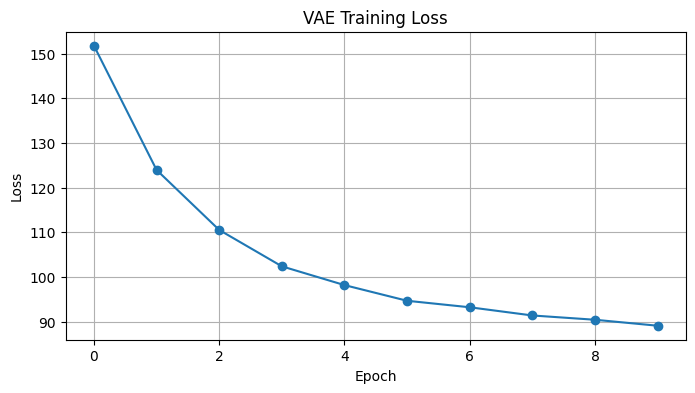

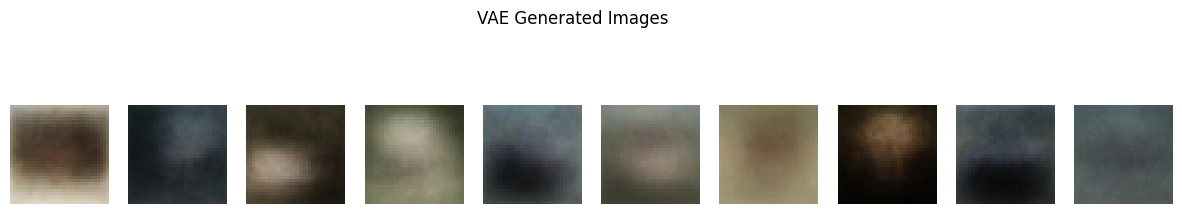

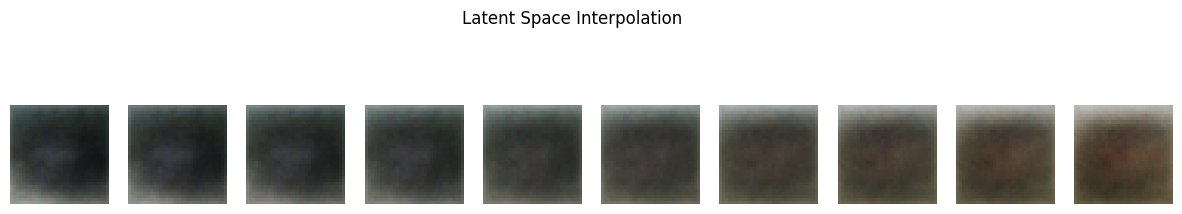

Image generation completed!
Latent space interpolation completed!


In [ ]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, Model

# 1. Load CIFAR-10 dataset
(x_train, _), (_, _) = tf.keras.datasets.cifar10.load_data()

# Normalize pixel values to the range [0, 1]
x_train = x_train.astype("float32") / 255.0

# Use a smaller subset to reduce training time and memory usage
x_train = x_train[:10000]

print("Dataset loaded successfully!")
print("Training data shape:", x_train.shape)

# 2. Define VAE parameters
latent_dim = 32
input_shape = (32, 32, 3)

# 3. Build the encoder
inputs = layers.Input(shape=input_shape)
x = layers.Flatten()(inputs)
x = layers.Dense(512, activation="relu")(x)
x = layers.Dense(256, activation="relu")(x)

z_mean = layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)

# Sampling from the latent distribution
def sampling(args):
    mean, log_var = args
    epsilon = tf.random.normal(shape=tf.shape(mean))
    return mean + tf.exp(0.5 * log_var) * epsilon

z = layers.Lambda(sampling, name="sampling")([z_mean, z_log_var])

encoder = Model(inputs, [z_mean, z_log_var, z], name="encoder")

# 4. Build the decoder
latent_inputs = layers.Input(shape=(latent_dim,))
x = layers.Dense(256, activation="relu")(latent_inputs)
x = layers.Dense(512, activation="relu")(x)
x = layers.Dense(32 * 32 * 3, activation="sigmoid")(x)
outputs = layers.Reshape(input_shape)(x)

decoder = Model(latent_inputs, outputs, name="decoder")

# 5. Build the VAE
class VAE(Model):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = tf.keras.metrics.Mean(name="loss")
        self.reconstruction_loss_tracker = tf.keras.metrics.Mean(
            name="reconstruction_loss"
        )
        self.kl_loss_tracker = tf.keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker,
        ]

    def train_step(self, data):
        if isinstance(data, tuple):
            data = data[0]

        with tf.GradientTape() as tape:
            mean, log_var, z = self.encoder(data, training=True)
            reconstruction = self.decoder(z, training=True)

            # Reconstruction loss
            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(
                    tf.square(data - reconstruction), axis=[1, 2, 3]
                )
            )

            # KL divergence loss
            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1 + log_var - tf.square(mean) - tf.exp(log_var),
                    axis=1,
                )
            )

            total_loss = reconstruction_loss + kl_loss

        gradients = tape.gradient(
            total_loss, self.trainable_weights
        )
        self.optimizer.apply_gradients(
            zip(gradients, self.trainable_weights)
        )

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(
            reconstruction_loss
        )
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss":
                self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

vae = VAE(encoder, decoder)
vae.compile(optimizer=tf.keras.optimizers.Adam())

# 6. Train the VAE
print("\nStarting VAE training...")
history = vae.fit(
    x_train,
    epochs=10,
    batch_size=64,
    shuffle=True
)

print("Training completed!")

# 7. Plot training loss
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], marker="o")
plt.title("VAE Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

# 8. Generate new images
num_images = 10
random_latent_vectors = tf.random.normal(
    shape=(num_images, latent_dim)
)
generated_images = decoder.predict(
    random_latent_vectors, verbose=0
)

plt.figure(figsize=(15, 3))
for i in range(num_images):
    plt.subplot(1, num_images, i + 1)
    plt.imshow(generated_images[i])
    plt.axis("off")

plt.suptitle("VAE Generated Images")
plt.show()

# 9. Latent space interpolation
z1 = tf.random.normal((1, latent_dim))
z2 = tf.random.normal((1, latent_dim))

interpolated_images = []

for alpha in np.linspace(0, 1, 10):
    z_interpolated = (1 - alpha) * z1 + alpha * z2
    image = decoder.predict(z_interpolated, verbose=0)[0]
    interpolated_images.append(image)

plt.figure(figsize=(15, 3))
for i, image in enumerate(interpolated_images):
    plt.subplot(1, 10, i + 1)
    plt.imshow(image)
    plt.axis("off")

plt.suptitle("Latent Space Interpolation")
plt.show()

print("Image generation completed!")
print("Latent space interpolation completed!")


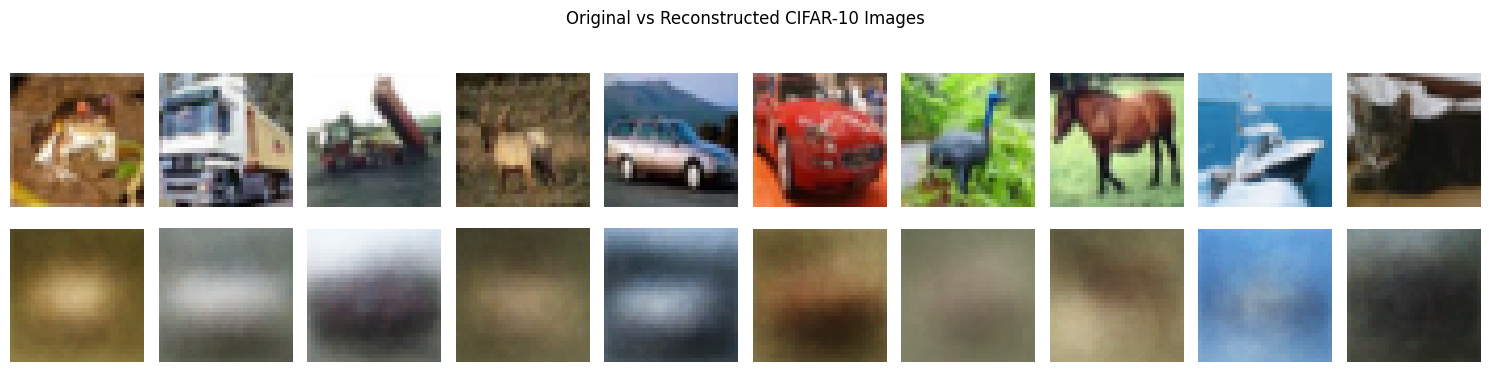

In [ ]:
# Compare original images with VAE reconstructions

original_images = x_train[:10]

mean, log_var, z = encoder.predict(original_images, verbose=0)
reconstructed_images = decoder.predict(z, verbose=0)

import matplotlib.pyplot as plt

plt.figure(figsize=(15, 4))

for i in range(10):
    # Original image
    plt.subplot(2, 10, i + 1)
    plt.imshow(original_images[i])
    plt.axis("off")
    if i == 0:
        plt.ylabel("Original")

    # Reconstructed image
    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed_images[i])
    plt.axis("off")
    if i == 0:
        plt.ylabel("Reconstructed")

plt.suptitle("Original vs Reconstructed CIFAR-10 Images")
plt.tight_layout()
plt.show()